In [1]:
import healpy as hp 
import numpy as np 
import matplotlib.pyplot as plt 
from tqdm import tqdm

def xylabels(dl=False):
    plt.ylabel(r"$C_\ell$")
    plt.xlabel(r"$\ell$")
    if dl: 
        plt.ylabel(r"$C_\ell \; \ell (\ell + 1)/2\pi$")

NSIDE = 512
npix = hp.nside2npix(NSIDE) 

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


**Notes**:

For this exercise, I will work with **healpix maps**.<br>
Healpix (healpy) is a code that transforms regular arrays into a pixelated sky map, i.e.,

```
m[pixel[RA,DEC]] = value_at_the_pixel
```
That is, it associates a value for each pixel of the sky (mathematically, we treat the sky as a unit sphere)

**Suggested Readings**:
- Ryden: Introduction to Cosmology
- Huterer: A course in cosmology

---
#  Revisiting Standard Rulers and Angular Diameter 

If we know the physical size of some object in the sky and its redshift, it's easy to compare with the angular diameter distance! 

Given that the predicted distance depends on the cosmological parameters, this is an amazing tool for probing the universe. 

$$L/\theta = d_A(z)$$
L is the physical size of some observed object, $\theta$ is the observed size, $d_A(z)$ is the angular diameter distance to the (observed) redshift of the object. 


## 1. A toy model of density perturbations 
In this exercise, we will explore how:
- The matter fluctuations create sound waves in the sky
- How we can "see" these waves


### 1.1 Single overdensity

Imagine we have an excess of matter in the early universe. 

This **overdensity** will induce a sound wave that will propagate through space, as beautifully illustrated here: 

![eisenstein2007](data/bao_2d_anim_1.gif)
Figure 1: A wave evolving from a single overdensity (Eisenstein et al. 2007)

Now let's simulate how this wave crest would appear in the sky. 

First, let's create a single ring around some arbitrary point (np.pi/2, np.pi/4). 
This ring will have a radius of 5 degrees and width of 0.1 degree. 

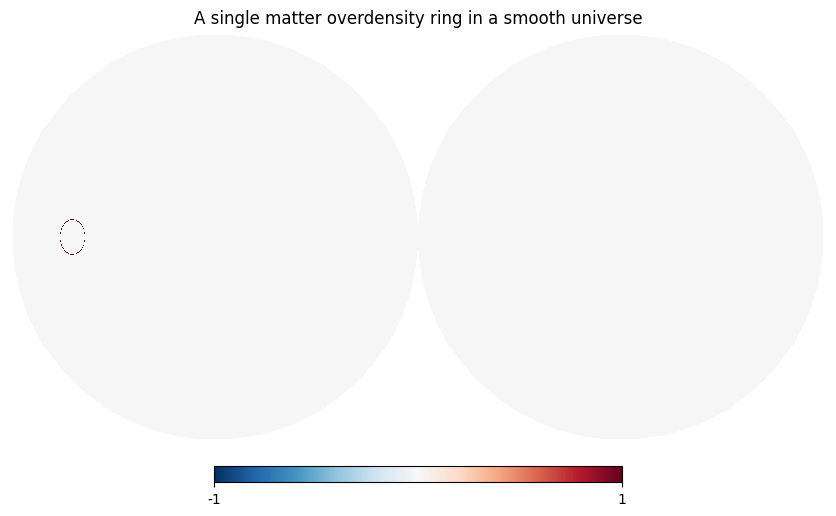

In [25]:
map_ring = np.zeros(npix)
fakeh = 5 # angle of radius of the ring in degrees
fake_width = .1 # width/2 of a single ring in degrees
ring_center = hp.ang2vec(np.pi/2, np.pi/4)

# getting a ring of overdensity: 
large_disc = hp.query_disc(NSIDE, ring_center, radius=np.radians(fakeh+fake_width))
inner_disc = hp.query_disc(NSIDE, ring_center, radius=np.radians(fakeh-fake_width))
single_ring = list(set(large_disc)-set(inner_disc))
single_rpix, single_rcount = np.unique(single_ring, return_counts=True)

# Adding the ring to the healpix map: 
map_ring[single_rpix]=1

hp.orthview(map_ring, cmap='RdBu_r', 
            min=-1, max=1,  
            title="A single matter overdensity ring in a smooth universe", hold=False)

### Multiple overdensities 
In the universe, we have several overdensities generating wave fronts! Let's create a toy model to simulate them. 

![eisenstein2007](data/bao_2d_anim_2.gif)


### Evolving the initial conditions: 

In our toy model, I will assume that around every overdensity a density fluctuation will propagate through space and it will freeze after some time. 

For this example, let's assume that overdensities such as $\delta>0.025$ (totally arbitrary number) will generate a sound wave. This sound wave will propagate for a given time until it has angular size of 5 degrees (arbitrary size for this example).

### 1.2 Initial random perturbation 
Below, we show you the density fluctuation field
$$\delta = (\rho - \rho_{mean})/\rho_{mean}$$

Let's start by assuming our matter is INITIALLY a Gaussian random field with
- positive fluctuations (red)
- negative fluctuations (blue)


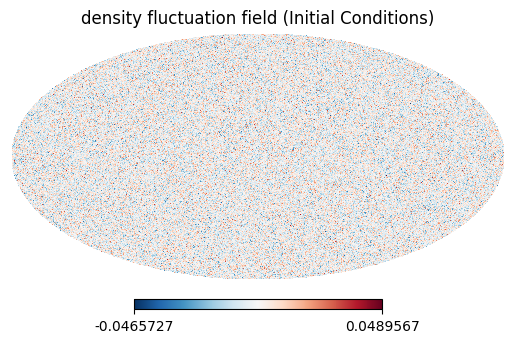

In [3]:
dd = np.random.normal(scale=1e-3, size=npix )*10 
hp.mollview(dd, cmap="RdBu_r", 
            hold=True, 
            title="density fluctuation field (Initial Conditions)")

Using healpy, we can check the power spectrum, using the function 
```
Cl = hp.anafast(YOUR_MAP)
```
it returns your angular power spectrum (also known as $C_\ell$) for the multipoles $\ell$, as defined below

Now, I will select the "seeds" for my toy model density waves: 

Number of rings: 71476


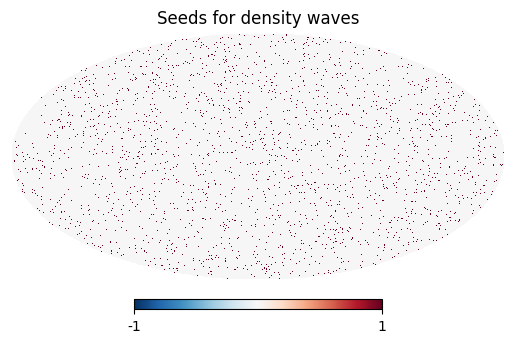

In [5]:
hp.mollview(dd>0.025, cmap="RdBu_r", 
            min=-1, max=1, title="Seeds for density waves", hold=True)
print(f"Number of rings: {np.sum(dd>0.02)}")

And then, after some computing time, I will have rings of overdensity with size of 5 degrees

In [6]:
%%time
overpix = np.where(dd>0.025)[0]
fakeh = 5
fake_width = 0.1
ring=[]
for idx in tqdm(overpix[:]):
    vec = hp.pix2vec(NSIDE,idx)

    large_disc = hp.query_disc(NSIDE, vec, radius=np.radians(fakeh+fake_width))
    inner_disc = hp.query_disc(NSIDE, vec, radius=np.radians(fakeh-fake_width))
    ring += list(set(large_disc)-set(inner_disc))
len(ring)/len(dd), len(ring)

rpix, rcount = np.unique(ring, return_counts=True)
print(len(rpix)/len(dd))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19424/19424 [00:17<00:00, 1142.31it/s]


0.9491847356160482
CPU times: user 17.6 s, sys: 278 ms, total: 17.9 s
Wall time: 17.8 s


Plot your rings map: 

## <font color='red'>Exercise 1: </font>
 
Based on the map above (discussion): 
1. Where are the overdensity rings?
2. Assuming one can still see them, what is their typical size?  

### Looking at the power spectrum 
The angular power spectrum, Cl, can again be evaluated from: 

In [17]:
clring= hp.anafast(ringmap)

# CMB skymaps

Now it is your turn to find overdensity scales in the Cosmic Microwave Background (CMB)

## 2.1 Loading maps 


In [14]:
# Loading simulated maps!
cmb0 = np.load("./data/cmb_sim0.npy")
cmb1 = np.load("./data/cmb_sim1.npy")
cmb2 = np.load("./data/cmb_sim2.npy")
cmb3 = np.load("./data/cmb_sim3.npy")
NSIDE = hp.npix2nside(cmb0.shape[0])
print(NSIDE)

512


## 2.2 Visualizing the map

In [ ]:
# Mollview is a projection of the spherical sky 
hp.mollview(cmb0, cmap="RdBu_r", title="CMB A")

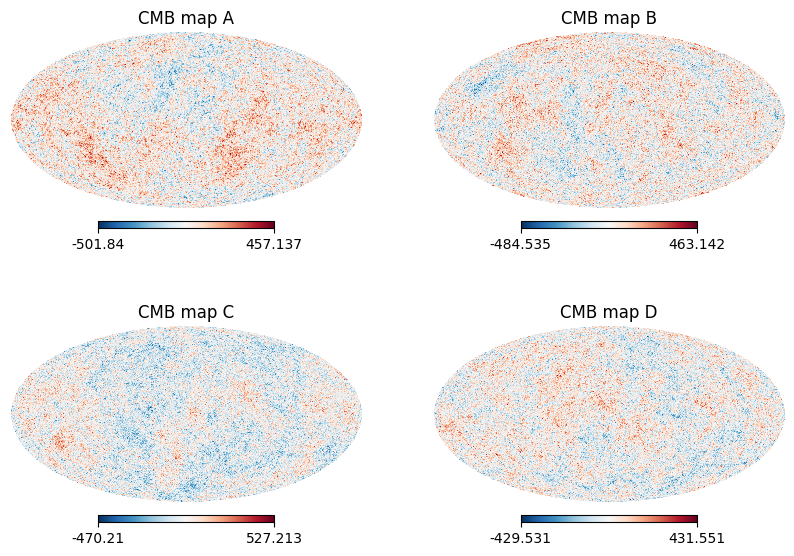

In [16]:
mosaic="""
ab
cd
"""
f, ax = plt.subplot_mosaic(mosaic, figsize=(10,7))
plt.sca(ax['a'])
hp.mollview(cmb0, cmap="RdBu_r", hold=True, title="CMB map A")
plt.sca(ax['b'])
hp.mollview(cmb1, cmap="RdBu_r", hold=True, title="CMB map B")
plt.sca(ax['c'])
hp.mollview(cmb2, cmap="RdBu_r", hold=True, title="CMB map C")
plt.sca(ax['d'])
hp.mollview(cmb3, cmap="RdBu_r", hold=True, title="CMB map D")

## 2.3 Analysing the maps 

## <font color='red'>Exercise 2: </font>

Again, precious map information is encoded in the Angular Power Spectrum.

1. BEFORE looking at the Angular Power Spectrum, describe the visual differences between these maps 
2. Use anafast and compute the Angular Power Spectrum of each map
3. Instead of Cl, plot:
     - $\ell \, (\ell + 1) C_\ell / 2\pi$
     - Use the range $2<\ell<900$
       
4. What are the differences between the observed power spectra? 

### 2.4 Did you find some large peaks in the Cl? 
#### The sound horizon: 

- Before the CMB is formed, photons and baryons are tightly coupled forming the photon-baryon fluid
- Density perturbations propagate in the photon-baryon fluid until the "moment" of recombination.
- The sound speed in the photon-baryon fluid is given by:
$$c_s = \frac{c}{\sqrt{3(1+R)}}$$

where R is the baryon-radiation $R\equiv \frac{3 \Omega_b}{4 \Omega_r} \, a$

- The maximum distance the wave perturbation propagates until the recombination is
$$r_s(z_*) = \int^{z_*}_{\infty} c_s(z) \frac{dz}{H(z)},$$
where the recombination happens at $z_*=1090$.

- The observed angle in the sky is then: 
$$\theta_s=\frac{r_s(z_*)}{D_M(z_*)} $$<br><br>

- This angle is, in terms of the multipole $\ell$: 
$$\ell_A \sim \frac{\pi}{\theta_s}= \pi\frac{D_M(z_*)}{r_s(z_*)}$$

## <font color='red'>Exercise 3: </font>

Assuming the Planck18 cosmology and the redshift of the recombination as $z_* = 1090$

1. Write a code for the D_M (comoving angular distance) and compute its value at the recombination
2. Compute the sound horizon at the recombination
3. Compute the angular size $\theta_s$ at which we should observe the peak of the density fluctuations in the CMB.
4. Compare with the Angular Power Spectrum you produced from the cmb simulated maps.
5. Compare the results with the theoretical prediction using `camb`. Let's discuss these results!


## Appendix: CAMB - Compute theoretical prediction of CMB Anisotropies

In [22]:
import camb
from camb import model, initialpower
import matplotlib.pyplot as plt
import numpy as np

# 1. Set up a new set of cosmological parameters
pars = camb.CAMBparams()

# Set standard LCDM parameters (Hubble, baryon density, cold dark matter density, etc.)
# H0 = 67.5, ombh2 = 0.022, omch2 = 0.122, mnu = 0.06, omk = 0, tau = 0.06
# Correct your values here:
pars.set_cosmology(H0=67.5, ombh2=0.022, omch2=0.122, mnu=0.06, omk=0.0, tau=0.06)

# Set the maximum multipole moment (l) for accuracy configurations
pars.set_for_lmax(2500, lens_potential_accuracy=0)

# 2. Calculate the results based on these parameters
results = camb.get_results(pars)

# 3. Extract the CMB power spectra (returns dict of numpy arrays)
# 'total' includes temperature, polarization, cross-correlations, and lensing effects
powers = results.get_cmb_power_spectra(pars, CMB_unit='muK')
totCL = powers['total']
Clcamb = totCL[:,0]

# The output format is an array indexed by l (from 0 to lmax)
# Columns represent: [TT, EE, BB, TE]
# The values returned are the standard D_l = l*(l+1)*C_l / 2pi
lcamb = np.arange(Clcamb.shape[0])

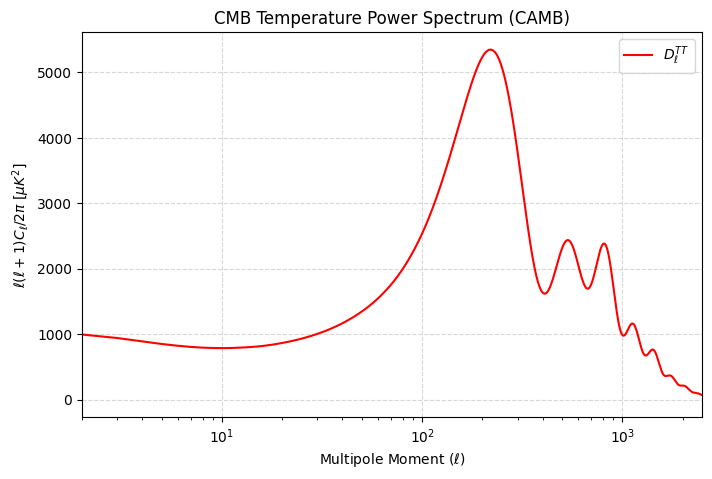

In [27]:
# 4. Plot the Temperature Anisotropy (TT) Power Spectrum
plt.figure(figsize=(8, 5))
plt.plot(lcamb, Clcamb, color='red', lw=1.5, label=r'$D_\ell^{TT}$')
plt.xlim(2, 2500)
plt.xscale('log')
plt.xlabel(r'Multipole Moment ($\ell$)')
plt.ylabel(r'$\ell(\ell+1)C_\ell / 2\pi$ [$\mu K^2$]')
plt.title('CMB Temperature Power Spectrum (CAMB)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend()
plt.show()